In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))    
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.config import GameConfig
from utils.results import evaluate_run
from utils.tables import experiment_tables, is_cournot
from utils.figures import BR_STYLE, OPT_STYLE, _style_ax, plot_cournot_heatmap

In [20]:
NAME = "asym2_sgd_uniform_oct8"          # used for the saved table files
BASE = dict(game="asym2", optimizer="sgd", run_n="uniform_oct6", l2_alpha=0.0, sgd_alpha_0=1e-3)
        #    two_sample=True, own_dist='stratified_pareto', opp_dist='pareto')
RUN_NS = ["uniform_oct8_s1", "uniform_oct8_s2", "uniform_oct8_s3", "uniform_oct8_s4", "uniform_oct8_s5"]
# RUN_NS = ["pareto_strat_s1", "pareto_strat_s2", "pareto_strat_s3", "pareto_strat_s4", "pareto_strat_s5"]
L2_ALPHA = 0.0
N_SETS = 5                            # opponent test sets per model

In [21]:
L2_ALPHA = BASE.get("l2_alpha", L2_ALPHA)
CONFIG_BASE = {k: v for k, v in BASE.items() if k not in ("l2_alpha", "run_n")}

results = [evaluate_run(run_n, GameConfig(**CONFIG_BASE, run_n=run_n), L2_ALPHA, n_sets=N_SETS)
           for run_n in RUN_NS]

Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s1/checkpoint_dir/ckpt-50 (step 5000000)
[uniform_oct8_s1] /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s1/checkpoint_dir/ckpt-50 (step 5,000,000)


Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s2/checkpoint_dir/ckpt-50 (step 5000000)
[uniform_oct8_s2] /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s2/checkpoint_dir/ckpt-50 (step 5,000,000)


Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s3/checkpoint_dir/ckpt-50 (step 5000000)
[uniform_oct8_s3] /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s3/checkpoint_dir/ckpt-50 (step 5,000,000)


Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s4/checkpoint_dir/ckpt-50 (step 5000000)
[uniform_oct8_s4] /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s4/checkpoint_dir/ckpt-50 (step 5,000,000)


Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s5/checkpoint_dir/ckpt-50 (step 5000000)
[uniform_oct8_s5] /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s5/checkpoint_dir/ckpt-50 (step 5,000,000)


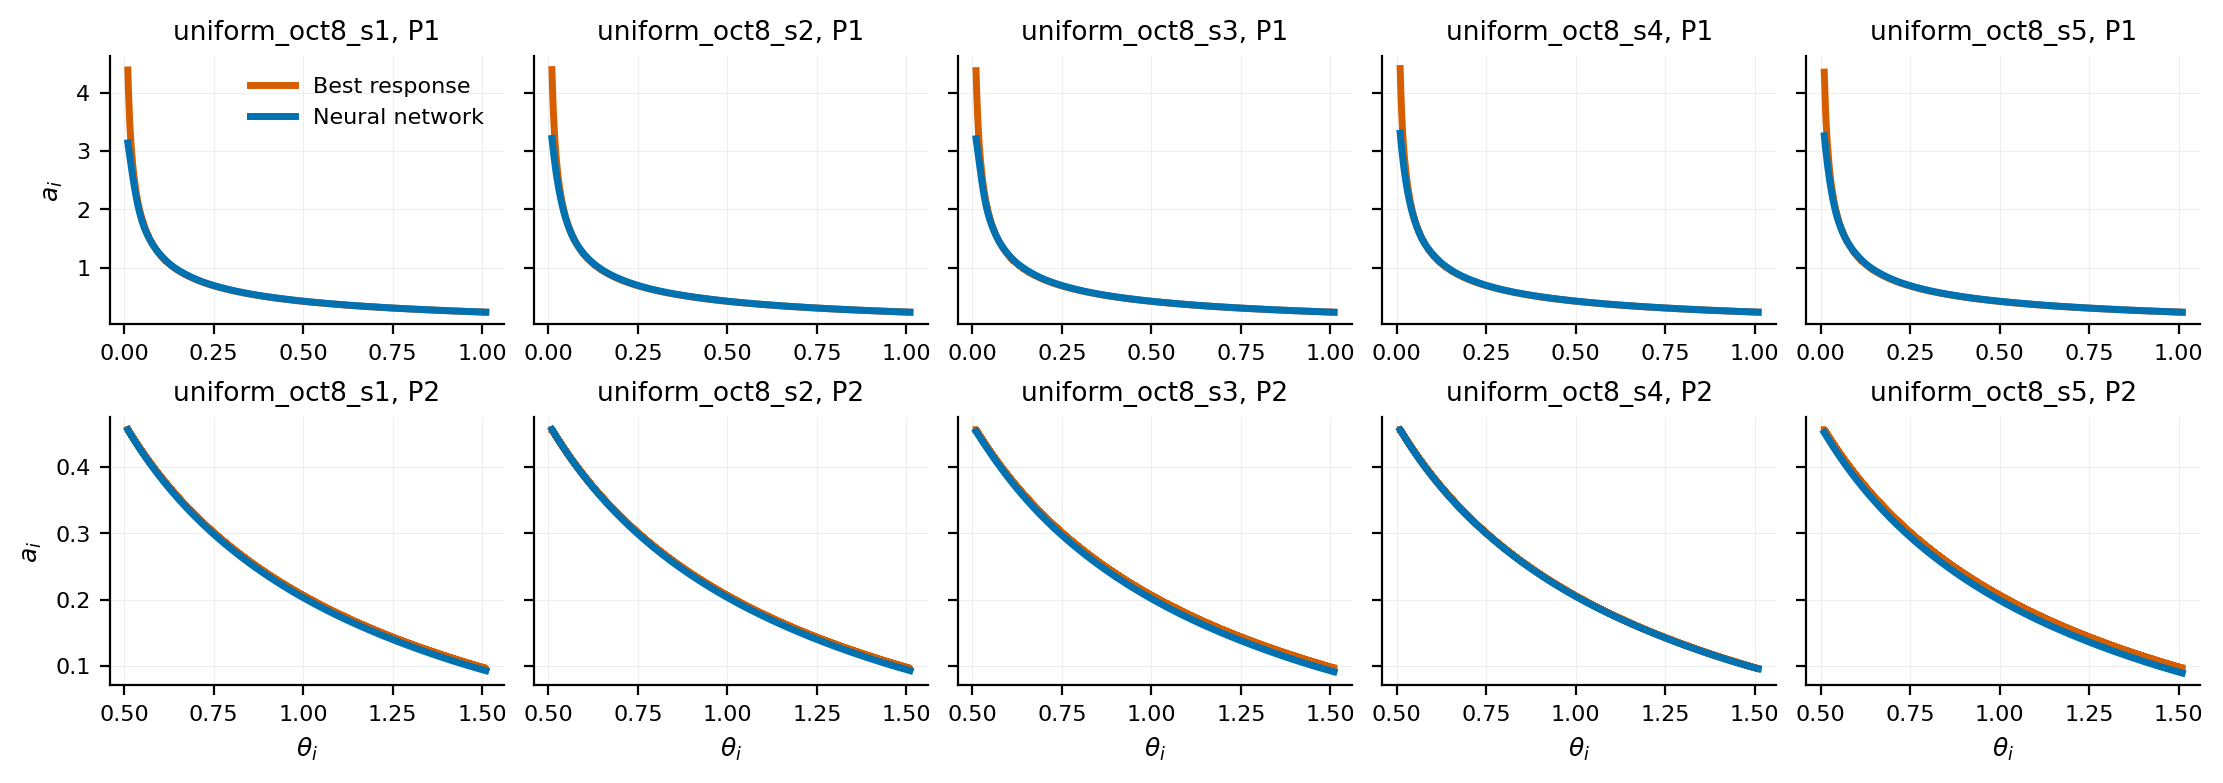

In [22]:
if is_cournot(results[0]):
    for r in results:
        print(r.label)
        plot_cournot_heatmap(r)
else:
    players = list(results[0].curves)
    fig, axes = plt.subplots(len(players), len(results),
                             figsize=(2.2 * len(results), 1.9 * len(players)), dpi=200,
                             sharey="row", squeeze=False, constrained_layout=True)
    for col, r in enumerate(results):
        for row, i in enumerate(players):
            c = r.curves[i]
            ax = axes[row, col]
            ax.plot(c["theta"], c["a_hat"], label="Best response", **BR_STYLE)
            ax.plot(c["theta"], c["a_nn"], label="Neural network", **OPT_STYLE["sgd"])
            title = r.label if len(players) == 1 else f"{r.label}, P{i + 1}"
            _style_ax(ax, xlabel=r"$\theta_i$" if row == len(players) - 1 else None,
                      ylabel=r"$a_i$" if col == 0 else None, title=title,
                      legend=(row == 0 and col == 0))
    plt.show()

In [23]:
tables = experiment_tables(results, NAME)


=== asym2_sgd_uniform_oct8: weights ===
             uniform_oct8_s1           uniform_oct8_s2           uniform_oct8_s3           uniform_oct8_s4           uniform_oct8_s5          
                    Player 1  Player 2        Player 1  Player 2        Player 1  Player 2        Player 1  Player 2        Player 1  Player 2
dense_1            4.949e-01 5.032e-01       4.995e-01 5.030e-01       4.886e-01 5.209e-01       4.926e-01 4.855e-01       4.825e-01 4.876e-01
dense_2            5.019e-01 5.040e-01       5.005e-01 5.042e-01       5.010e-01 5.063e-01       5.003e-01 5.017e-01       5.004e-01 5.007e-01
dense_3            5.008e-01 5.044e-01       5.032e-01 4.999e-01       5.006e-01 5.130e-01       5.007e-01 5.013e-01       5.012e-01 4.997e-01
dense_4            4.999e-01 5.013e-01       4.999e-01 5.006e-01       4.994e-01 5.025e-01       5.006e-01 5.004e-01       4.999e-01 5.006e-01
dense_5            4.999e-01 5.009e-01       5.024e-01 5.011e-01       5.024e-01 5.120e-01       5.00

In [24]:
def model_summary(r):
    """One number per metric for one model (averaged over its opponent test sets)."""
    rel = r.test["relative_loss"]
    row = {"Step": r.step, "Train merit": r.train_merit["total"]}
    for w, sets in rel.items():
        row[f"Relative loss ({w})"] = np.mean([s["strategy"] for s in sets])
    row["Max utility loss"] = np.mean(
        [max(p["max_loss"] for p in s["per_player"].values()) for s in rel["uniform"]])
    return row

per_model = pd.DataFrame({r.label: model_summary(r) for r in results}).T
across = per_model.drop(columns="Step").agg(["mean", "std"])

print("=== Per model ===")
print(per_model.to_string(float_format=lambda v: f"{v:.3e}"))
print(f"\n=== Across {len(results)} models (std with ddof = 1) ===")
print(across.to_string(float_format=lambda v: f"{v:.3e}"))
print()
for col in across.columns:
    print(f"{col:<28} {across.loc['mean', col]:.3e} ± {across.loc['std', col]:.3e}")

=== Per model ===
                     Step  Train merit  Relative loss (uniform)  Max utility loss
uniform_oct8_s1 5.000e+06    1.149e-06                1.090e-04         5.155e-03
uniform_oct8_s2 5.000e+06    1.065e-06                1.082e-04         4.506e-03
uniform_oct8_s3 5.000e+06    1.409e-06                8.848e-05         4.416e-03
uniform_oct8_s4 5.000e+06    1.276e-06                1.483e-04         3.883e-03
uniform_oct8_s5 5.000e+06    1.605e-06                1.035e-04         3.854e-03

=== Across 5 models (std with ddof = 1) ===
      Train merit  Relative loss (uniform)  Max utility loss
mean    1.301e-06                1.115e-04         4.363e-03
std     2.141e-07                2.216e-05         5.339e-04

Train merit                  1.301e-06 ± 2.141e-07
Relative loss (uniform)      1.115e-04 ± 2.216e-05
Max utility loss             4.363e-03 ± 5.339e-04


In [25]:
def check_types(results, types):
    """Network action, best response and utilities at the grid types closest to `types`,
    for every model and player (types outside a player's range are skipped)."""
    rows = []
    for r in results:
        for i, c in r.curves.items():
            th = c["theta"]
            for t in types:
                if not (th.min() <= t <= th.max()):
                    continue
                k = int(np.argmin(np.abs(th - t)))
                rows.append(dict(model=r.label, player=i + 1, theta=th[k],
                                 a_nn=c["a_nn"][k], a_br=c["a_hat"][k],
                                 a_diff=c["a_nn"][k] - c["a_hat"][k],
                                 rho_nn=c["rho_nn"][k], rho_br=c["rho_hat"][k],
                                 utility_loss=c["rho_hat"][k] - c["rho_nn"][k]))
    return pd.DataFrame(rows)


checks = check_types(results, [0.01])
print(checks.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

print("\nAcross models (mean ± std):")
for (player, theta), g in checks.groupby(["player", "theta"]):
    print(f"player {player}, theta {theta:.4g}: a_nn {g.a_nn.mean():.4g} ± {g.a_nn.std():.2g}   "
          f"a_br {g.a_br.mean():.4g} ± {g.a_br.std():.2g}")

          model  player  theta  a_nn  a_br  a_diff  rho_nn  rho_br  utility_loss
uniform_oct8_s1       1   0.01 3.142 4.394  -1.252  0.9049  0.9095      0.004642
uniform_oct8_s2       1   0.01 3.218   4.4  -1.182  0.9054  0.9094       0.00403
uniform_oct8_s3       1   0.01 3.213 4.382  -1.169  0.9059  0.9098      0.003943
uniform_oct8_s4       1   0.01 3.308 4.419  -1.111  0.9056  0.9091      0.003453
uniform_oct8_s5       1   0.01 3.264 4.357  -1.093  0.9069  0.9103      0.003414

Across models (mean ± std):
player 1, theta 0.01: a_nn 3.229 ± 0.062   a_br 4.391 ± 0.023


In [26]:
from utils.loading import load_model
from utils.evaluation import make_evaluator


def low_type_diagnostics(r, theta_star=0.01, window=(0.01, 0.1), player=0, rel_h=1e-3):
    """For one model and player:
    1. max utility loss rho_hat - rho over grid types in `window`;
    2. curvature of rho in the action at the best response, at theta_star, by central differences
       (with the exact second derivative as a check);
    3. utility loss at theta_star.
    Uses the same opponents as the figures' curves (evaluator seed 0)."""
    c = r.curves[player]
    th = c["theta"]
    loss = c["rho_hat"] - c["rho_nn"]

    in_window = (th >= window[0]) & (th <= window[1])
    k = int(np.argmin(np.abs(th - theta_star)))
    a_br = float(c["a_hat"][k])

    # opponents' total bid S, from the same opponent pool as the curves
    model, _ = load_model(r.config, r.l2_alpha)
    ev = make_evaluator(model, r.config, r.game_def)
    opp = dict(ev.matchups())[player]
    b = ev.opponent_pool(opp).numpy().ravel().astype(np.float64)
    n_players = r.game_def.get("n_players", r.game_def["n"])
    S = b if n_players == 2 else (b[:, None] + b[None, :]).ravel()

    rho = lambda a: np.mean(a / (a + S)) - th[k] * a          # expected utility, float64
    h = rel_h * max(a_br, 1e-6)
    kappa = abs(rho(a_br + h) - 2 * rho(a_br) + rho(a_br - h)) / h ** 2
    kappa_exact = 2 * np.mean(S / (a_br + S) ** 3)             # |rho''(a)| for this payoff

    return dict(model=r.label, player=player + 1,
                max_loss_window=float(loss[in_window].max()),
                theta=float(th[k]), a_br=a_br, a_nn=float(c["a_nn"][k]),
                kappa=kappa, kappa_exact=kappa_exact,
                loss_at_theta=float(loss[k]))


diag = pd.DataFrame([low_type_diagnostics(r) for r in results])
print(diag.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

print("\nAcross models (mean ± std):")
for col, name in [("max_loss_window", "1. max utility loss, theta in [0.01, 0.1]"),
                  ("kappa", "2. curvature at theta = 0.01"),
                  ("loss_at_theta", "3. utility loss at theta = 0.01")]:
    print(f"{name:<42} {diag[col].mean():.4e} ± {diag[col].std():.2e}")

Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s1/checkpoint_dir/ckpt-50 (step 5000000)
Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s2/checkpoint_dir/ckpt-50 (step 5000000)


Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s3/checkpoint_dir/ckpt-50 (step 5000000)
Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s4/checkpoint_dir/ckpt-50 (step 5000000)


Restored from /Users/andresho/Desktop/Continuous-Type-BNE/saved_models/asym2/sgd_uniform_oct8_s5/checkpoint_dir/ckpt-50 (step 5000000)
          model  player  max_loss_window  theta  a_br  a_nn    kappa  kappa_exact  loss_at_theta
uniform_oct8_s1       1         0.004642   0.01 4.394 3.142 0.004309     0.004309       0.004642
uniform_oct8_s2       1          0.00403   0.01   4.4 3.218 0.004298     0.004298        0.00403
uniform_oct8_s3       1         0.003943   0.01 4.382 3.213 0.004314     0.004314       0.003943
uniform_oct8_s4       1         0.003453   0.01 4.419 3.308 0.004275     0.004275       0.003453
uniform_oct8_s5       1         0.003414   0.01 4.357 3.264 0.004345     0.004345       0.003414

Across models (mean ± std):
1. max utility loss, theta in [0.01, 0.1]  3.8963e-03 ± 5.01e-04
2. curvature at theta = 0.01               4.3082e-03 ± 2.55e-05
3. utility loss at theta = 0.01            3.8963e-03 ± 5.01e-04
